# 💳 Credit Card Fraud Detection (Imbalanced Classification + Explainability)

**Problem:** 284,807 credit card transactions (2 din ka data), jisme sirf **492 fraud (0.172%)** hain. Hume fraud pakadna hai bina normal customers ko zyada pareshan kiye.

**Is notebook me kya hota hai:**
1. **Time-based split** (purane transactions pe train, naye pe test), random split nahi
2. Sahi metrics: **PR-AUC** (accuracy bekaar hai is data me), precision / recall / F1, **Precision@K** (analyst review budget)
3. **5 models compare:** Dummy, Logistic Regression, LR + SMOTE, Random Forest, LightGBM (tuned)
4. **Threshold selection** validation pe (F1-optimal aur **cost-optimal**), test pe sirf final check
5. **Business cost simulation:** fraud miss karne ka loss vs false alarm ka review cost
6. **Explainability:** LightGBM ke native SHAP contributions se global aur per-transaction explanations
7. Model + threshold save (aage Streamlit app ke liye)

**Dataset:** https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

**Kaggle setup:** Add Input, dataset add karo (path auto-detect hota hai). GPU/Internet ki zaroorat nahi. Run time ~10 min.

## 1. Setup & Config

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             roc_curve, confusion_matrix, f1_score)
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except Exception:
    HAS_SMOTE = False

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# ------------------------------ CONFIG ------------------------------
SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15      # baaki 15% test (time order me)
REVIEW_COST = 5.0                      # ASSUMPTION: ek false alarm review karne ka cost (EUR)
N_TUNE_TRIALS = 10                     # LightGBM random search trials
DEPLOY_MODEL = "LightGBM (tuned)"      # thresholds, SHAP aur saved model isi ke hain (RF jaise models sirf comparison ke liye)
MAX_ROUNDS, EARLY_STOP = 1000, 50
# --------------------------------------------------------------------

np.random.seed(SEED)
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
SEARCH_ROOTS = [r for r in ["/kaggle/input", "."] if os.path.exists(r)]
print("LightGBM:", lgb.__version__, "| SMOTE available:", HAS_SMOTE, "| Output dir:", OUT_DIR)

LightGBM: 4.6.0 | SMOTE available: True | Output dir: /kaggle/working


## 2. Load Data (path auto-detect)

In [2]:
def find_csv(name="creditcard.csv"):
    for root in SEARCH_ROOTS:
        for dirpath, _, files in os.walk(root):
            if name in files:
                return os.path.join(dirpath, name)
    raise FileNotFoundError("creditcard.csv nahi mila. Kaggle me 'Add Input' se dataset add karo.")

path = find_csv()
print("File:", path)
raw = pd.read_csv(path)
print("Shape:", raw.shape)
raw.head()

File: /kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Data Quality Checks

In [3]:
print("Missing values  :", int(raw.isna().sum().sum()))
n_dup = int(raw.duplicated().sum())
print("Duplicate rows  :", n_dup)

df = raw.drop_duplicates().sort_values("Time").reset_index(drop=True)
print("After dedup     :", df.shape)

vc = df["Class"].value_counts()
print(f"\nClass counts -> normal: {vc[0]:,} | fraud: {vc[1]:,} | fraud rate: {100 * vc[1] / len(df):.3f}%")

# Accuracy kyun bekaar hai: sab kuch 'normal' bolne wala model
print(f"Accuracy of 'always normal' model: {100 * vc[0] / len(df):.2f}%  (par ek bhi fraud nahi pakadta)")
print(f"Fraud amount: mean {df.loc[df.Class == 1, 'Amount'].mean():.2f} | "
      f"normal amount: mean {df.loc[df.Class == 0, 'Amount'].mean():.2f}")

Missing values  : 0
Duplicate rows  : 1081
After dedup     : (283726, 31)

Class counts -> normal: 283,253 | fraud: 473 | fraud rate: 0.167%
Accuracy of 'always normal' model: 99.83%  (par ek bhi fraud nahi pakadta)
Fraud amount: mean 123.87 | normal amount: mean 88.41


## 4. Exploratory Data Analysis

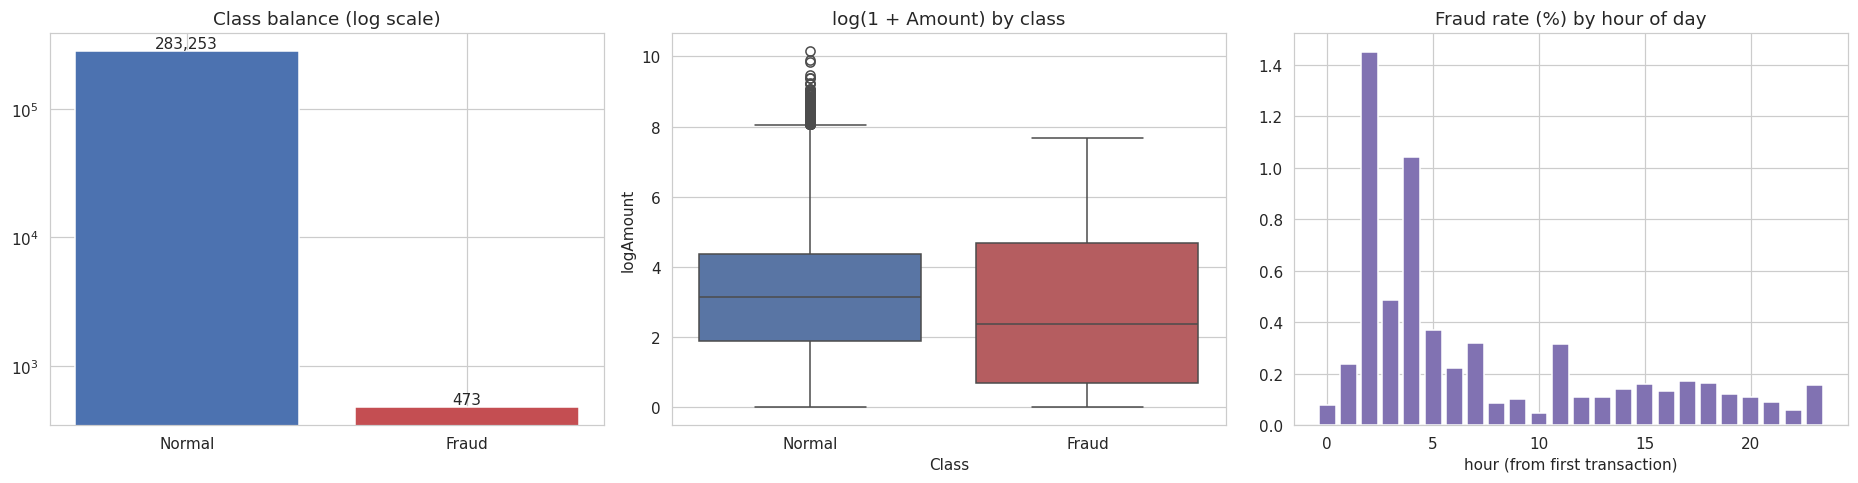

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# Class balance
ax[0].bar(["Normal", "Fraud"], [vc[0], vc[1]], color=["#4C72B0", "#C44E52"])
ax[0].set_yscale("log"); ax[0].set_title("Class balance (log scale)")
for i, v in enumerate([vc[0], vc[1]]):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")

# Amount by class
sns.boxplot(data=df.assign(logAmount=np.log1p(df["Amount"])), x="Class", y="logAmount", ax=ax[1],
            palette=["#4C72B0", "#C44E52"])
ax[1].set_xticklabels(["Normal", "Fraud"]); ax[1].set_title("log(1 + Amount) by class")

# Fraud rate by hour of day
hour = ((df["Time"] // 3600) % 24).astype(int)
rate = df.groupby(hour)["Class"].agg(["mean", "sum", "count"])
ax[2].bar(rate.index, 100 * rate["mean"], color="#8172B2")
ax[2].set_title("Fraud rate (%) by hour of day"); ax[2].set_xlabel("hour (from first transaction)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "eda_overview.png"), dpi=150); plt.show()

Top correlated with fraud: {'V17': -0.313, 'V14': -0.293, 'V12': -0.251, 'V10': -0.207, 'V16': -0.187, 'V3': -0.182}


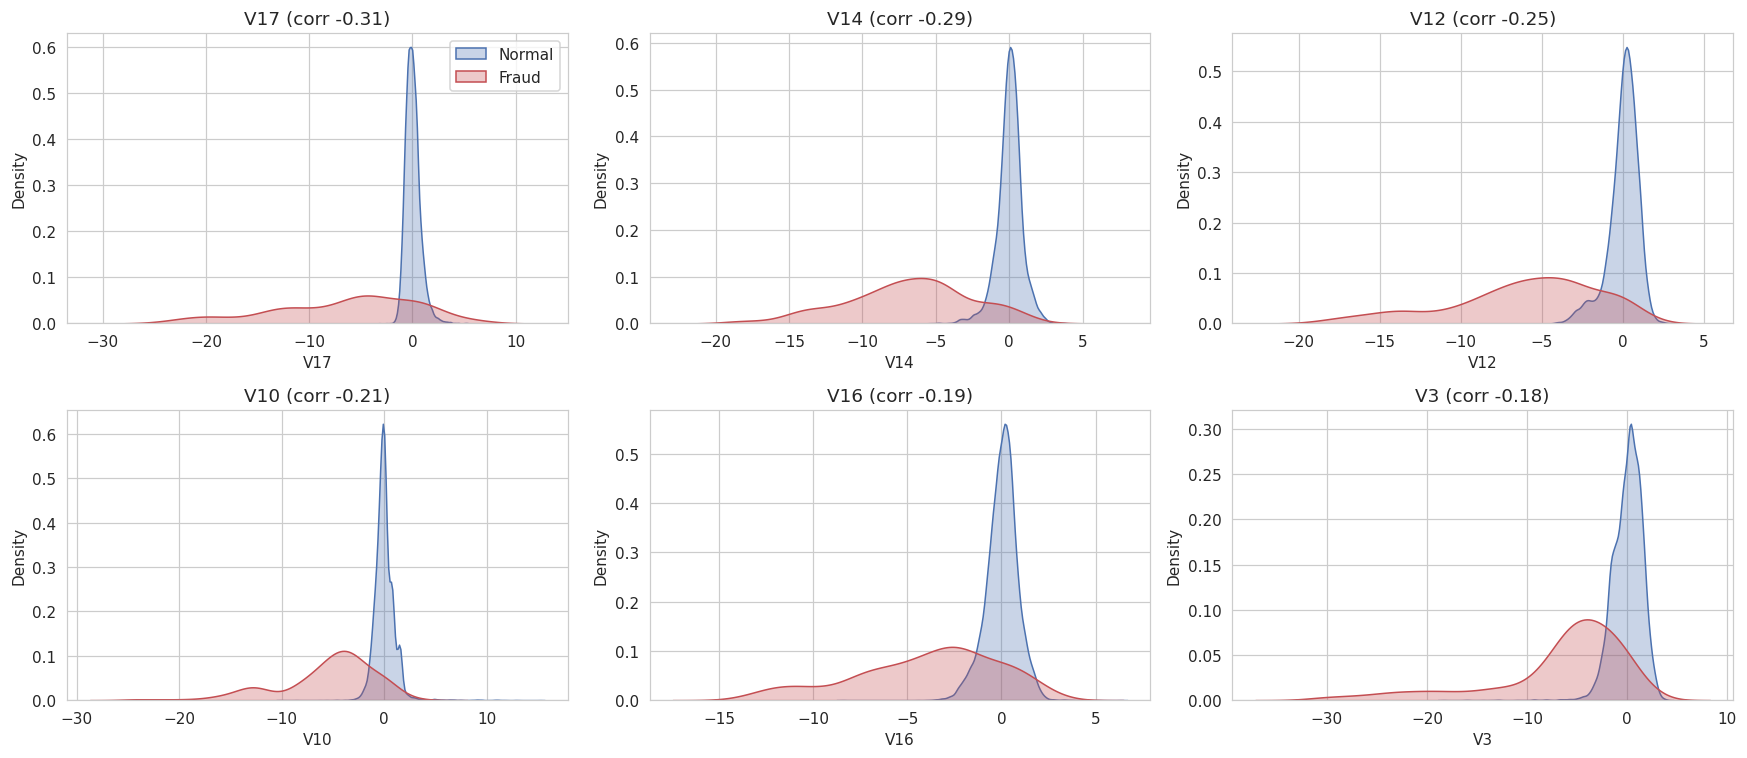

In [5]:
# Kaun se features fraud aur normal me sabse alag hain?
feat_cols = [c for c in df.columns if c.startswith("V")]
corr = df[feat_cols + ["Class"]].corr()["Class"].drop("Class").sort_values(key=np.abs, ascending=False)
top_feats = list(corr.head(6).index)
print("Top correlated with fraud:", {k: round(v, 3) for k, v in corr.head(6).items()})

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax_, f in zip(axes.ravel(), top_feats):
    sns.kdeplot(df.loc[df.Class == 0, f].sample(min(20000, (df.Class == 0).sum()), random_state=SEED),
                ax=ax_, label="Normal", color="#4C72B0", fill=True, alpha=0.3)
    sns.kdeplot(df.loc[df.Class == 1, f], ax=ax_, label="Fraud", color="#C44E52", fill=True, alpha=0.3)
    ax_.set_title(f"{f} (corr {corr[f]:+.2f})")
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "eda_top_features.png"), dpi=150); plt.show()

## 5. Feature Engineering & Time-Based Split

- `V1..V28` pehle se PCA features hain. `Amount` ko `log1p` karte hain. `Time` (seconds) ko **hour-of-day** (sin/cos) me badalte hain.
- **Split time order me:** pehle 70% transactions train, agle 15% validation, aakhri 15% test. Real life me bhi model purane data pe train hota hai aur naye transactions pe chalta hai.
- Validation se model selection aur threshold, **test sirf aakhir me ek baar**.

In [6]:
def make_features(d):
    out = d[feat_cols].copy()
    out["log_amount"] = np.log1p(d["Amount"])
    h = (d["Time"] // 3600) % 24
    out["hour_sin"] = np.sin(2 * np.pi * h / 24)
    out["hour_cos"] = np.cos(2 * np.pi * h / 24)
    return out

X_all = make_features(df)
y_all = df["Class"].values
amount_all = df["Amount"].values
FEATURES = list(X_all.columns)

n = len(df)
i_tr, i_va = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
sl = {"train": slice(0, i_tr), "val": slice(i_tr, i_va), "test": slice(i_va, n)}

X_tr, y_tr = X_all.iloc[sl["train"]], y_all[sl["train"]]
X_va, y_va, amt_va = X_all.iloc[sl["val"]], y_all[sl["val"]], amount_all[sl["val"]]
X_te, y_te, amt_te = X_all.iloc[sl["test"]], y_all[sl["test"]], amount_all[sl["test"]]

for name, y in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(f"{name:5s}: {len(y):>7,} rows | frauds {int(y.sum()):>4} ({100 * y.mean():.3f}%)")
assert min(y_tr.sum(), y_va.sum(), y_te.sum()) >= 10, "Kisi split me fraud bahut kam hain"
print("Features:", len(FEATURES))

train: 198,608 rows | frauds  366 (0.184%)
val  :  42,559 rows | frauds   55 (0.129%)
test :  42,559 rows | frauds   52 (0.122%)
Features: 31


## 6. Metrics

Fraud jaise imbalanced problem me **accuracy mat dekho**. Hum dekhte hain:
- **PR-AUC (Average Precision):** main metric
- **ROC-AUC:** reference ke liye
- **Precision / Recall / F1** ek chune hue threshold pe
- **Precision@K:** agar analysts sirf K sabse risky transactions review kar sakte hain
- **Business cost:** missed fraud ka amount + false alarms ka review cost

In [7]:
def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(threshold=float(thr), tp=tp, fp=fp, fn=fn, tn=tn, precision=prec, recall=rec, f1=f1)

def business_cost(y, p, thr, amount, review_cost=REVIEW_COST):
    pred = p >= thr
    missed = float(amount[(y == 1) & (~pred)].sum())          # miss hua fraud: poora amount loss
    alarms = int(pred.sum()) * review_cost                       # har flag ka review cost
    return missed + alarms, missed, alarms

def precision_at_k(y, p, k):
    top = np.argsort(-p)[:k]
    return float(y[top].mean())

def recall_at_k(y, p, k):
    top = np.argsort(-p)[:k]
    return float(y[top].sum() / max(y.sum(), 1))

def summary_row(name, y, p, thr=None):
    row = {"Model": name, "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p)}
    if thr is not None:
        m = metrics_at(y, p, thr)
        row.update({"Precision": m["precision"], "Recall": m["recall"], "F1": m["f1"]})
    return row

## 7. Models

| Model | Imbalance handling |
|---|---|
| Dummy | sirf class prior (kuch seekhta nahi) |
| Logistic Regression | `class_weight="balanced"` |
| Logistic Regression + SMOTE | training me synthetic fraud samples |
| Random Forest | `class_weight="balanced_subsample"` |
| LightGBM (tuned) | `scale_pos_weight` + random search |

In [8]:
scaler = StandardScaler().fit(X_tr)
Xs_tr, Xs_va, Xs_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te)

val_proba, test_proba, fit_times = {}, {}, {}

def run(name, model, Xtr, ytr, Xva, Xte):
    t0 = time.time()
    model.fit(Xtr, ytr)
    val_proba[name] = model.predict_proba(Xva)[:, 1]
    test_proba[name] = model.predict_proba(Xte)[:, 1]
    fit_times[name] = time.time() - t0
    print(f"{name:28s} val PR-AUC {average_precision_score(y_va, val_proba[name]):.4f} | "
          f"val ROC-AUC {roc_auc_score(y_va, val_proba[name]):.4f} | {fit_times[name]:.0f}s")
    return model

run("Dummy", DummyClassifier(strategy="prior"), Xs_tr, y_tr, Xs_va, Xs_te)
lr = run("Logistic Regression", LogisticRegression(class_weight="balanced", max_iter=2000, C=0.5),
         Xs_tr, y_tr, Xs_va, Xs_te)

if HAS_SMOTE:
    Xsm, ysm = SMOTE(sampling_strategy=0.1, random_state=SEED).fit_resample(Xs_tr, y_tr)
    print(f"SMOTE: train fraud share {100 * y_tr.mean():.3f}% -> {100 * ysm.mean():.2f}%")
    run("Logistic Regression + SMOTE", LogisticRegression(max_iter=2000, C=0.5), Xsm, ysm, Xs_va, Xs_te)
else:
    print("imbalanced-learn nahi mila, SMOTE comparison skip.")

rf = run("Random Forest",
         RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=3, n_jobs=-1,
                                class_weight="balanced_subsample", random_state=SEED),
         X_tr, y_tr, X_va, X_te)

Dummy                        val PR-AUC 0.0013 | val ROC-AUC 0.5000 | 0s
Logistic Regression          val PR-AUC 0.8089 | val ROC-AUC 0.9813 | 1s
SMOTE: train fraud share 0.184% -> 9.09%
Logistic Regression + SMOTE  val PR-AUC 0.8038 | val ROC-AUC 0.9772 | 1s
Random Forest                val PR-AUC 0.8653 | val ROC-AUC 0.9885 | 89s


## 8. LightGBM with Random Search

`scale_pos_weight`, tree size aur regularization ke random configs try karte hain. Har config ko **validation PR-AUC** pe early stopping ke saath judge karte hain.

In [9]:
rng = np.random.default_rng(SEED)
ratio = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
space = dict(
    num_leaves=[15, 31, 63], learning_rate=[0.03, 0.05, 0.1], min_child_samples=[20, 50, 100],
    feature_fraction=[0.7, 0.9, 1.0], bagging_fraction=[0.7, 0.9, 1.0], lambda_l2=[0.0, 1.0, 5.0],
    scale_pos_weight=[1.0, float(np.sqrt(ratio)), float(ratio)],
)

ds_params = {"feature_pre_filter": False}      # trials me min_child_samples badalta hai, isliye
dtrain = lgb.Dataset(X_tr, label=y_tr, params=ds_params, free_raw_data=False)
dval = lgb.Dataset(X_va, label=y_va, reference=dtrain, params=ds_params, free_raw_data=False)

def lgb_params(cfg):
    return dict(objective="binary", metric="average_precision", bagging_freq=1, verbose=-1,
                seed=SEED, deterministic=True, force_row_wise=True, **cfg)

trials = []
for t in range(N_TUNE_TRIALS):
    cfg = {k: v[rng.integers(len(v))] for k, v in space.items()}
    t0 = time.time()
    b = lgb.train(lgb_params(cfg), dtrain, num_boost_round=MAX_ROUNDS, valid_sets=[dval],
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    score = b.best_score["valid_0"]["average_precision"]
    trials.append({**cfg, "best_iter": b.best_iteration, "val_PR_AUC": score})
    print(f"trial {t + 1:2d}/{N_TUNE_TRIALS}: val PR-AUC {score:.4f} | iters {b.best_iteration:4d} | {time.time() - t0:.0f}s | {cfg}")

tune_df = pd.DataFrame(trials).sort_values("val_PR_AUC", ascending=False).reset_index(drop=True)
display(tune_df.head(5).round(4))

trial  1/10: val PR-AUC 0.8375 | iters   48 | 2s | {'num_leaves': 15, 'learning_rate': 0.1, 'min_child_samples': 50, 'feature_fraction': 0.9, 'bagging_fraction': 0.9, 'lambda_l2': 5.0, 'scale_pos_weight': 1.0}
trial  2/10: val PR-AUC 0.7827 | iters 1000 | 23s | {'num_leaves': 63, 'learning_rate': 0.03, 'min_child_samples': 20, 'feature_fraction': 0.9, 'bagging_fraction': 1.0, 'lambda_l2': 5.0, 'scale_pos_weight': 541.6448087431694}
trial  3/10: val PR-AUC 0.8013 | iters  923 | 20s | {'num_leaves': 63, 'learning_rate': 0.1, 'min_child_samples': 50, 'feature_fraction': 0.7, 'bagging_fraction': 1.0, 'lambda_l2': 1.0, 'scale_pos_weight': 23.273263818020226}
trial  4/10: val PR-AUC 0.8269 | iters  843 | 18s | {'num_leaves': 31, 'learning_rate': 0.03, 'min_child_samples': 100, 'feature_fraction': 1.0, 'bagging_fraction': 0.9, 'lambda_l2': 1.0, 'scale_pos_weight': 541.6448087431694}
trial  5/10: val PR-AUC 0.5434 | iters    2 | 1s | {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples

,num_leaves,learning_rate,min_child_samples,feature_fraction,bagging_fraction,lambda_l2,scale_pos_weight,best_iter,val_PR_AUC
0,31,0.03,100,1.0,1.0,5.0,23.2733,168,0.8457
1,15,0.10,50,0.9,0.9,5.0,1.0000,48,0.8375
2,31,0.03,100,1.0,0.9,1.0,541.6448,843,0.8269
3,63,0.10,20,0.9,0.9,1.0,1.0000,598,0.8123
4,63,0.10,50,0.7,1.0,1.0,23.2733,923,0.8013


In [10]:
best = tune_df.iloc[0]
best_cfg = {k: float(best[k]) for k in space}
for k in ("num_leaves", "min_child_samples"):
    best_cfg[k] = int(best_cfg[k])
BEST_ITER = int(best["best_iter"])

t0 = time.time()
booster = lgb.train(lgb_params(best_cfg), dtrain, num_boost_round=BEST_ITER)
fit_times["LightGBM (tuned)"] = time.time() - t0
val_proba["LightGBM (tuned)"] = booster.predict(X_va)
test_proba["LightGBM (tuned)"] = booster.predict(X_te)
print("Best config:", best_cfg, "| rounds:", BEST_ITER)
print(f"LightGBM (tuned) val PR-AUC {average_precision_score(y_va, val_proba['LightGBM (tuned)']):.4f}")

Best config: {'num_leaves': 31, 'learning_rate': 0.03, 'min_child_samples': 100, 'feature_fraction': 1.0, 'bagging_fraction': 1.0, 'lambda_l2': 5.0, 'scale_pos_weight': 23.273263818020226} | rounds: 168
LightGBM (tuned) val PR-AUC 0.8457


## 9. Model Comparison (Validation)

,Model,PR-AUC,ROC-AUC
3,Random Forest,0.8653,0.9885
4,LightGBM (tuned),0.8457,0.9824
1,Logistic Regression,0.8089,0.9813
2,Logistic Regression + SMOTE,0.8038,0.9772
0,Dummy,0.0013,0.5000


Best on validation (PR-AUC): Random Forest
Deployed model: LightGBM (tuned) (val PR-AUC gap to best: 0.0196)


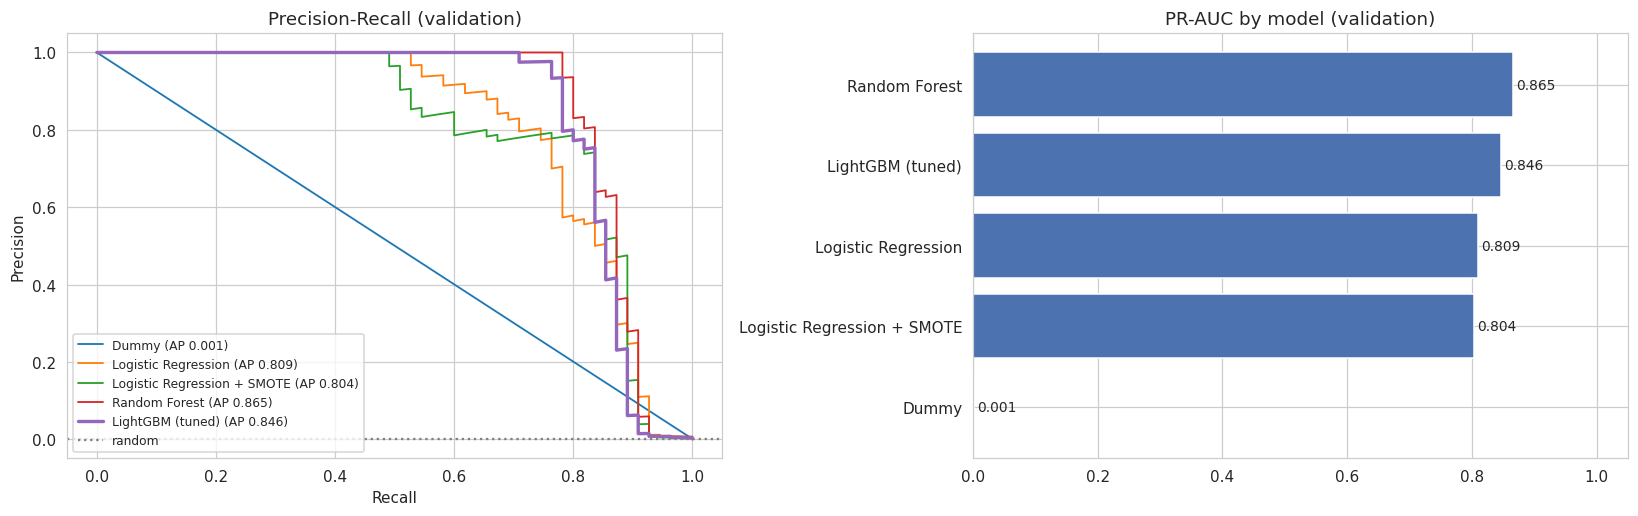

In [11]:
val_tbl = pd.DataFrame([summary_row(m, y_va, p) for m, p in val_proba.items()]).sort_values("PR-AUC", ascending=False)
display(val_tbl.round(4))

BEST_MODEL = val_tbl.iloc[0]["Model"]
print("Best on validation (PR-AUC):", BEST_MODEL)
gap = float(val_tbl.iloc[0]["PR-AUC"] - val_tbl.loc[val_tbl["Model"] == DEPLOY_MODEL, "PR-AUC"].iloc[0])
print(f"Deployed model: {DEPLOY_MODEL} (val PR-AUC gap to best: {gap:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for m, p in val_proba.items():
    pr, rc, _ = precision_recall_curve(y_va, p)
    ax[0].plot(rc, pr, label=f"{m} (AP {average_precision_score(y_va, p):.3f})", lw=2.2 if m == DEPLOY_MODEL else 1.2)
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-Recall (validation)")
ax[0].axhline(y_va.mean(), color="gray", ls=":", label="random"); ax[0].legend(fontsize=8)

order = val_tbl.sort_values("PR-AUC")
ax[1].barh(order["Model"], order["PR-AUC"], color="#4C72B0")
for y_, v in enumerate(order["PR-AUC"]): ax[1].text(v + 0.005, y_, f"{v:.3f}", va="center", fontsize=9)
ax[1].set_title("PR-AUC by model (validation)"); ax[1].set_xlim(0, 1.05)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "model_comparison.png"), dpi=150); plt.show()

## 10. Threshold Selection (validation only)

Model probability deta hai, par alert tab jata hai jab probability **threshold** se upar ho. Do operating points chunte hain:

- **F1-optimal:** precision aur recall ka balance
- **Cost-optimal:** missed fraud ka amount + `REVIEW_COST x false alarms` minimum

> `REVIEW_COST` ek **assumption** hai (config cell me badal sakte ho). Asli bank apna cost dalega.

F1-optimal threshold   : 0.8300
Cost-optimal threshold : 0.6400


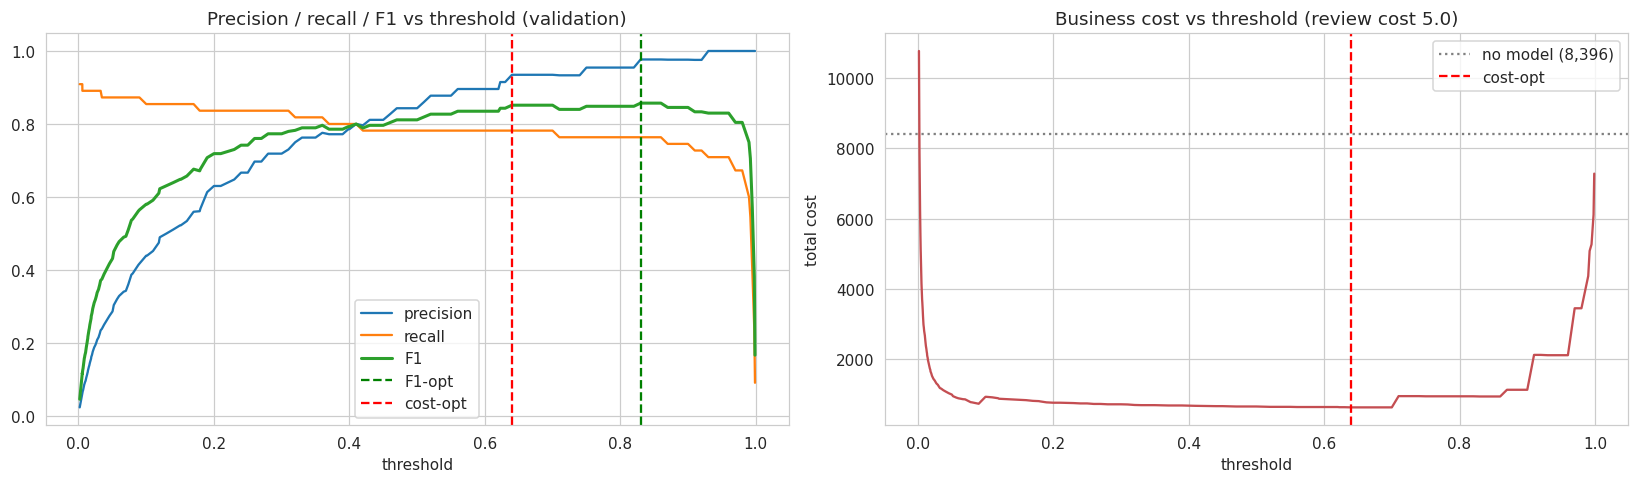

In [12]:
p_val = val_proba[DEPLOY_MODEL]
cand = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(p_val, np.linspace(0.95, 0.9999, 250))]))

grid = []
for thr in cand:
    m = metrics_at(y_va, p_val, thr)
    total, missed, alarms = business_cost(y_va, p_val, thr, amt_va)
    grid.append({**m, "cost": total, "missed_loss": missed, "review_cost": alarms})
grid = pd.DataFrame(grid)

THR_F1 = float(grid.loc[grid["f1"].idxmax(), "threshold"])
THR_COST = float(grid.loc[grid["cost"].idxmin(), "threshold"])
print(f"F1-optimal threshold   : {THR_F1:.4f}")
print(f"Cost-optimal threshold : {THR_COST:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(grid["threshold"], grid["precision"], label="precision")
ax[0].plot(grid["threshold"], grid["recall"], label="recall")
ax[0].plot(grid["threshold"], grid["f1"], label="F1", lw=2)
ax[0].axvline(THR_F1, color="green", ls="--", label="F1-opt"); ax[0].axvline(THR_COST, color="red", ls="--", label="cost-opt")
ax[0].set_xlabel("threshold"); ax[0].set_title("Precision / recall / F1 vs threshold (validation)"); ax[0].legend()
no_model = float(amt_va[y_va == 1].sum())
ax[1].plot(grid["threshold"], grid["cost"], color="#C44E52")
ax[1].axhline(no_model, color="gray", ls=":", label=f"no model ({no_model:,.0f})")
ax[1].axvline(THR_COST, color="red", ls="--", label="cost-opt")
ax[1].set_xlabel("threshold"); ax[1].set_ylabel("total cost"); ax[1].set_title(f"Business cost vs threshold (review cost {REVIEW_COST})"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "threshold_selection.png"), dpi=150); plt.show()

## 11. Final Test Evaluation (ek baar)

Test set (sabse naye 15% transactions) pe thresholds **validation se** liye gaye hain. Test ke basis pe kuch tune nahi hua.

Deployed model **LightGBM (tuned)** hai (fast, native SHAP). Baaki models sirf comparison ke liye hain.

In [13]:
p_te = test_proba[DEPLOY_MODEL]

rows = []
for name, p in test_proba.items():
    r = summary_row(name, y_te, p, thr=None)
    if name == DEPLOY_MODEL:
        m_ = metrics_at(y_te, p, THR_F1)
        r.update({"Precision": m_["precision"], "Recall": m_["recall"], "F1": m_["f1"]})
    rows.append(r)
test_tbl = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)
display(test_tbl.round(4))

print(f"\n=== {DEPLOY_MODEL} on TEST ({len(y_te):,} transactions, {int(y_te.sum())} frauds) ===")
op_rows = []
for label, thr in [("F1-optimal", THR_F1), ("Cost-optimal", THR_COST)]:
    m = metrics_at(y_te, p_te, thr)
    total, missed, alarms = business_cost(y_te, p_te, thr, amt_te)
    op_rows.append({"Operating point": label, "Threshold": thr, "Precision": m["precision"], "Recall": m["recall"],
                    "F1": m["f1"], "Caught": m["tp"], "Missed": m["fn"], "False alarms": m["fp"],
                    "Total cost": total, "Missed loss": missed, "Review cost": alarms})
op_tbl = pd.DataFrame(op_rows)
display(op_tbl.round(4))

no_model_te = float(amt_te[y_te == 1].sum())
best_cost = op_tbl["Total cost"].min()
print(f"Cost without a model (all fraud missed): {no_model_te:,.2f}")
print(f"Cost with model (best operating point) : {best_cost:,.2f}  -> saving {100 * (1 - best_cost / no_model_te):.1f}%")
print(f"PR-AUC {average_precision_score(y_te, p_te):.4f} | ROC-AUC {roc_auc_score(y_te, p_te):.4f}")

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1
3,Random Forest,0.7731,0.9493,NaN,NaN,NaN
4,LightGBM (tuned),0.7516,0.9758,0.9024,0.7115,0.7957
2,Logistic Regression + SMOTE,0.6999,0.9717,NaN,NaN,NaN
1,Logistic Regression,0.6921,0.9766,NaN,NaN,NaN
0,Dummy,0.0012,0.5000,NaN,NaN,NaN



=== LightGBM (tuned) on TEST (42,559 transactions, 52 frauds) ===


,Operating point,Threshold,Precision,Recall,F1,Caught,Missed,False alarms,Total cost,Missed loss,Review cost
0,F1-optimal,0.83,0.9024,0.7115,0.7957,37,15,4,2657.28,2452.28,205.0
1,Cost-optimal,0.64,0.7647,0.7500,0.7573,39,13,12,2627.40,2372.40,255.0


Cost without a model (all fraud missed): 6,168.88
Cost with model (best operating point) : 2,627.40  -> saving 57.4%
PR-AUC 0.7516 | ROC-AUC 0.9758


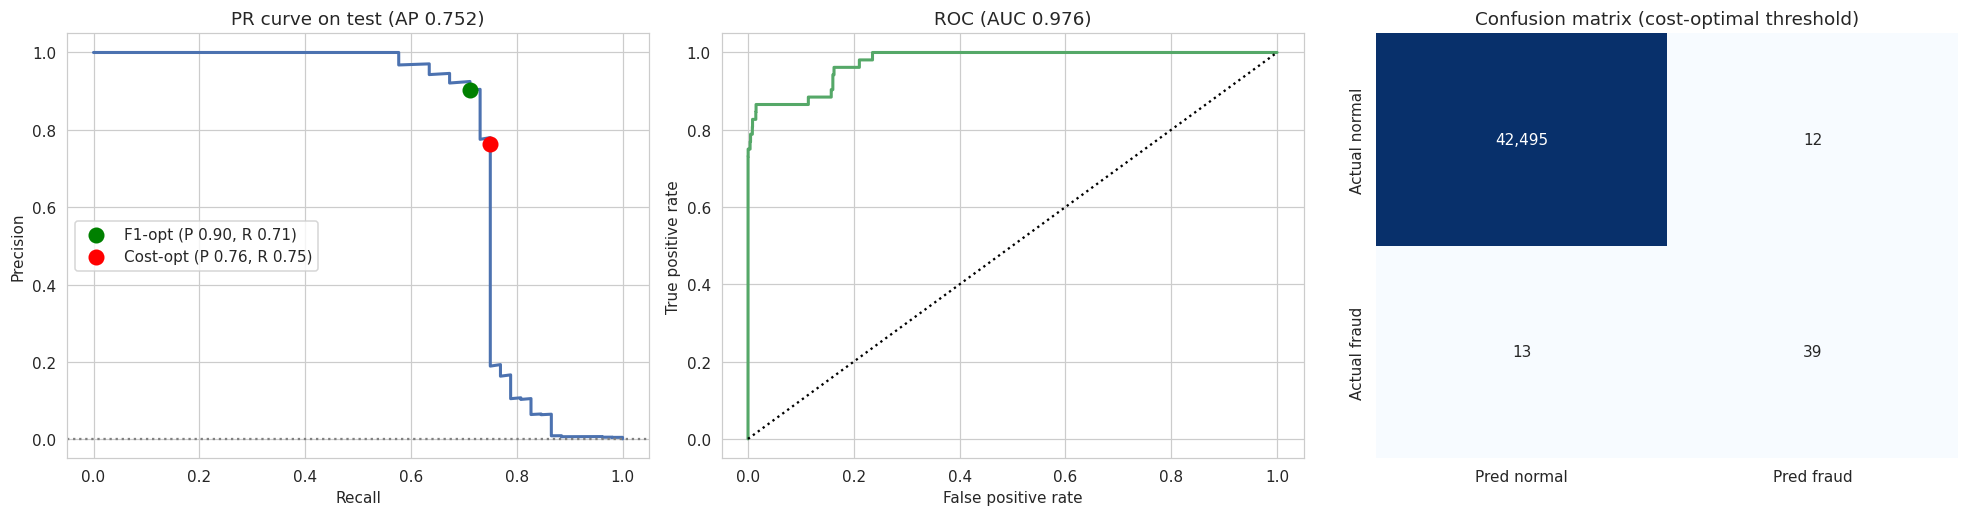

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

# PR curve with operating points
pr, rc, _ = precision_recall_curve(y_te, p_te)
ax[0].plot(rc, pr, color="#4C72B0", lw=2)
for label, thr, c in [("F1-opt", THR_F1, "green"), ("Cost-opt", THR_COST, "red")]:
    m = metrics_at(y_te, p_te, thr)
    ax[0].scatter(m["recall"], m["precision"], s=90, color=c, zorder=5, label=f"{label} (P {m['precision']:.2f}, R {m['recall']:.2f})")
ax[0].axhline(y_te.mean(), color="gray", ls=":")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title(f"PR curve on test (AP {average_precision_score(y_te, p_te):.3f})"); ax[0].legend()

# ROC
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[1].plot(fpr, tpr, color="#55A868", lw=2); ax[1].plot([0, 1], [0, 1], "k:")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title(f"ROC (AUC {roc_auc_score(y_te, p_te):.3f})")

# Confusion matrix at cost-optimal
m = metrics_at(y_te, p_te, THR_COST)
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[2],
            xticklabels=["Pred normal", "Pred fraud"], yticklabels=["Actual normal", "Actual fraud"])
ax[2].set_title("Confusion matrix (cost-optimal threshold)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "test_evaluation.png"), dpi=150); plt.show()

,K (reviewed),Precision@K,Recall@K
0,10,1.000,0.192
1,25,1.000,0.481
2,50,0.780,0.750
3,100,0.390,0.750
4,200,0.195,0.750
5,500,0.086,0.827


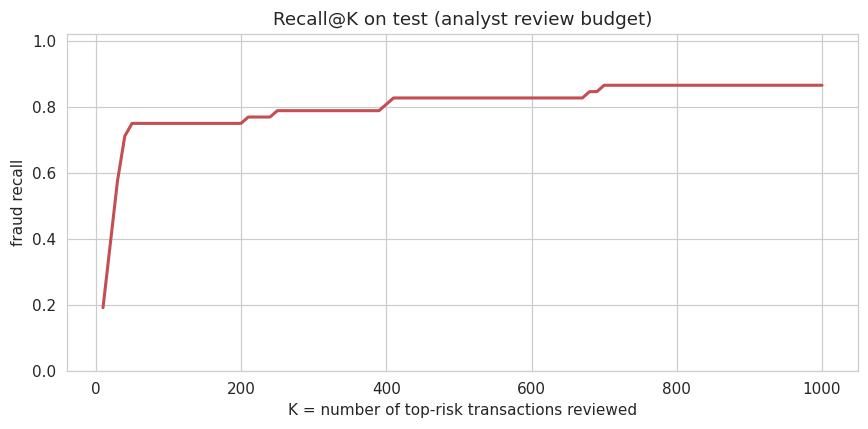

In [15]:
# Analyst review budget: sabse risky K transactions review karein toh?
ks = [10, 25, 50, 100, 200, 500]
bud = pd.DataFrame({"K (reviewed)": ks,
                    "Precision@K": [precision_at_k(y_te, p_te, k) for k in ks],
                    "Recall@K": [recall_at_k(y_te, p_te, k) for k in ks]})
display(bud.round(3))

kk = np.arange(10, 1001, 10)
plt.figure(figsize=(8, 4))
plt.plot(kk, [recall_at_k(y_te, p_te, k) for k in kk], color="#C44E52", lw=2)
plt.xlabel("K = number of top-risk transactions reviewed"); plt.ylabel("fraud recall")
plt.title("Recall@K on test (analyst review budget)"); plt.ylim(0, 1.02)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "recall_at_k.png"), dpi=150); plt.show()

## 12. Error Analysis

In [16]:
# Missed fraud vs caught fraud: amount ke hisaab se
pred_c = p_te >= THR_COST
seg = pd.DataFrame({"y": y_te, "pred": pred_c, "amount": amt_te})
seg["bucket"] = pd.cut(seg["amount"], [-0.01, 10, 50, 200, 1e9], labels=["<=10", "10-50", "50-200", ">200"])
by = seg[seg.y == 1].groupby("bucket", observed=True).agg(frauds=("y", "size"), caught=("pred", "sum"))
by["recall"] = by["caught"] / by["frauds"]
print("Fraud recall by amount bucket (cost-optimal threshold):")
display(by.round(3))

n_fa = int(((seg.pred) & (seg.y == 0)).sum())
print("\nFalse alarms:", n_fa, "of", int((seg.y == 0).sum()), "normal transactions",
      f"({100 * n_fa / (seg.y == 0).sum():.3f}%)")
has_missed = ((seg.y == 1) & ~seg.pred).any()
has_caught = ((seg.y == 1) & seg.pred).any()
print("Median amount: caught fraud", round(float(seg[(seg.y == 1) & seg.pred]["amount"].median()), 2) if has_caught else "n/a",
      "| missed fraud", round(float(seg[(seg.y == 1) & ~seg.pred]["amount"].median()), 2) if has_missed else "n/a")

Fraud recall by amount bucket (cost-optimal threshold):


,frauds,caught,recall
bucket,,,
<=10,29,23,0.793
10-50,7,4,0.571
50-200,7,6,0.857
>200,9,6,0.667



False alarms: 12 of 42507 normal transactions (0.028%)
Median amount: caught fraud 4.69 | missed fraud 12.31


## 13. Explainability (native SHAP from LightGBM)

LightGBM `predict(..., pred_contrib=True)` har feature ka **SHAP contribution** deta hai (extra library ki zaroorat nahi).
Positive value = transaction ko fraud ki taraf dhakelti hai.

,V4,V14,V8,hour_sin,V12,V22,V5,V18,V20,V3
mean |SHAP|,0.3615,0.3391,0.2929,0.2466,0.1691,0.1403,0.1107,0.1066,0.1034,0.1017


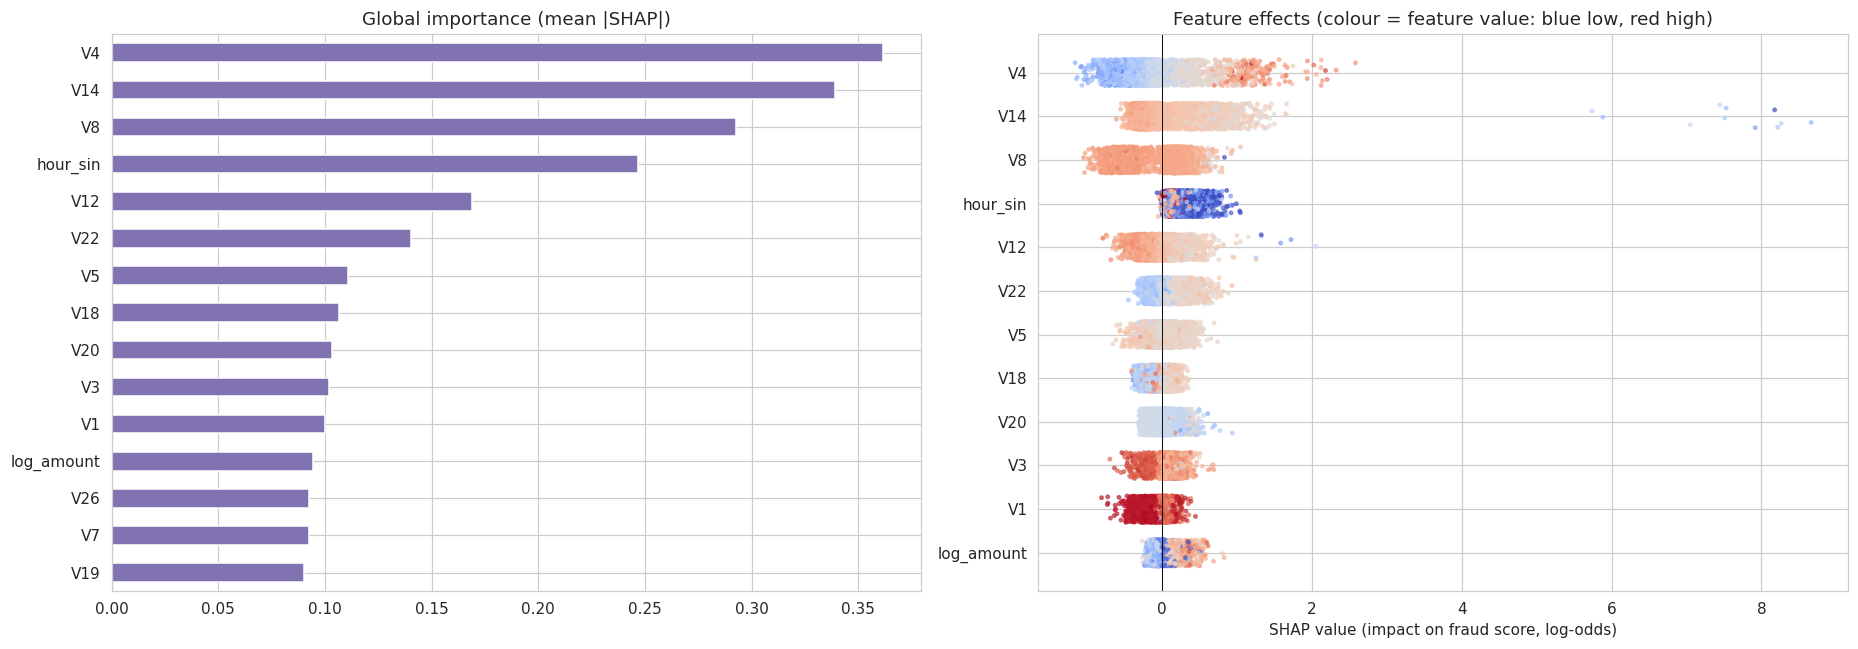

In [17]:
contrib_te = booster.predict(X_te, pred_contrib=True)         # (n, features + 1), last column = bias
shap_te, bias_te = contrib_te[:, :-1], contrib_te[:, -1]

imp = pd.Series(np.abs(shap_te).mean(axis=0), index=FEATURES).sort_values(ascending=False)
display(imp.head(10).round(4).to_frame("mean |SHAP|").T)

# Global importance + beeswarm-style (top 12)
top = list(imp.head(12).index)
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
imp.head(15).iloc[::-1].plot(kind="barh", ax=ax[0], color="#8172B2")
ax[0].set_title("Global importance (mean |SHAP|)")

rs = np.random.default_rng(SEED)
sample = rs.choice(len(X_te), size=min(4000, len(X_te)), replace=False)
for row, f in enumerate(top[::-1]):
    j = FEATURES.index(f)
    vals = X_te.iloc[sample, j].values
    rngv = np.ptp(vals) or 1.0
    col = (vals - vals.min()) / rngv
    ax[1].scatter(shap_te[sample, j], row + rs.uniform(-0.3, 0.3, len(sample)), c=col, cmap="coolwarm", s=5, alpha=0.6)
ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels(top[::-1])
ax[1].axvline(0, color="k", lw=0.6); ax[1].set_xlabel("SHAP value (impact on fraud score, log-odds)")
ax[1].set_title("Feature effects (colour = feature value: blue low, red high)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "shap_summary.png"), dpi=150); plt.show()

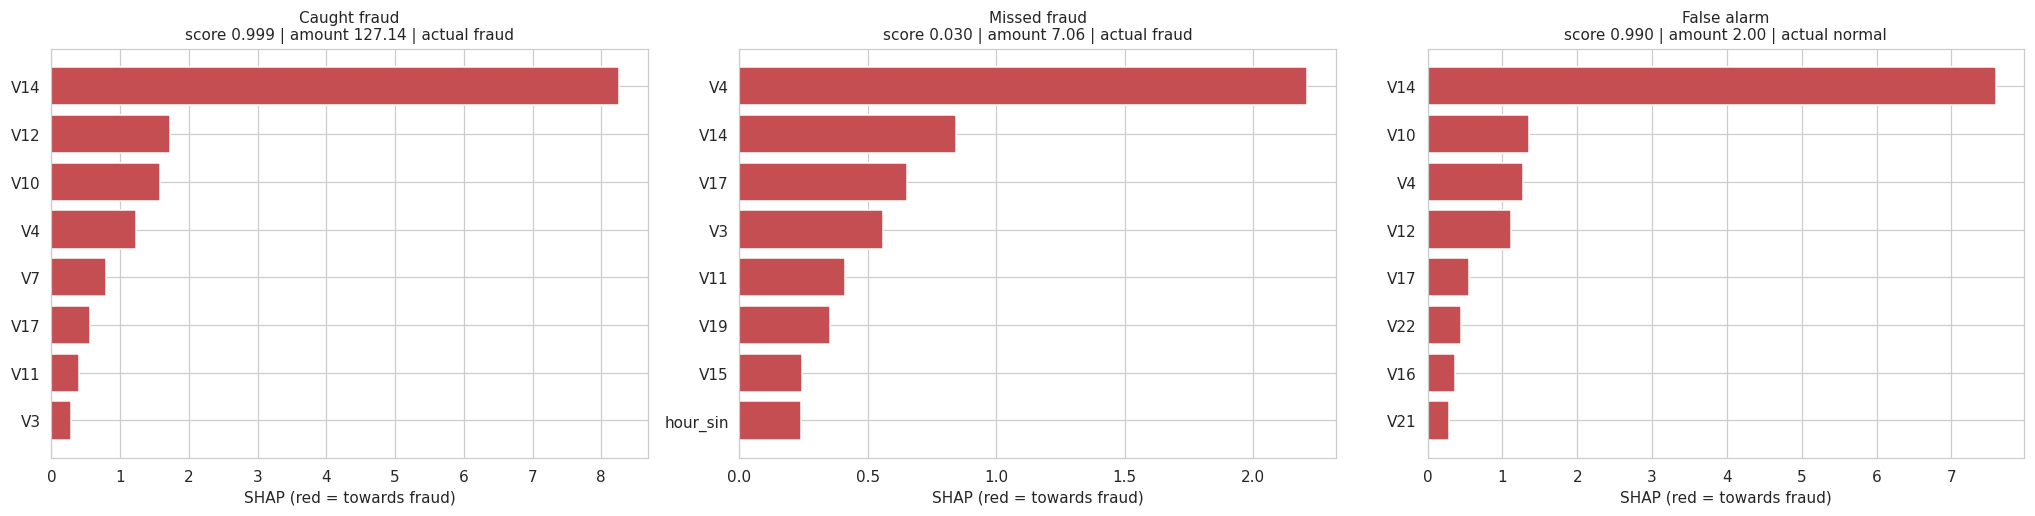

In [18]:
# Local explanations: ek pakda gaya fraud, ek missed fraud, ek false alarm
pred_c = p_te >= THR_COST
cases = {}
caught = np.where((y_te == 1) & pred_c)[0]
missed = np.where((y_te == 1) & ~pred_c)[0]
falsea = np.where((y_te == 0) & pred_c)[0]
if len(caught): cases["Caught fraud"] = caught[np.argmax(p_te[caught])]
if len(missed): cases["Missed fraud"] = missed[np.argmax(p_te[missed])]
if len(falsea): cases["False alarm"] = falsea[np.argmax(p_te[falsea])]

fig, axes = plt.subplots(1, len(cases), figsize=(6.2 * len(cases), 4.8))
axes = np.atleast_1d(axes)
for ax_, (title, i) in zip(axes, cases.items()):
    s = pd.Series(shap_te[i], index=FEATURES)
    show = s.reindex(s.abs().sort_values(ascending=False).head(8).index).iloc[::-1]
    ax_.barh(show.index, show.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in show.values])
    ax_.axvline(0, color="k", lw=0.6)
    ax_.set_title(f"{title}\nscore {p_te[i]:.3f} | amount {amt_te[i]:.2f} | actual {'fraud' if y_te[i] else 'normal'}", fontsize=10)
    ax_.set_xlabel("SHAP (red = towards fraud)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "shap_local.png"), dpi=150); plt.show()

## 14. Save Artifacts

In [19]:
booster.save_model(os.path.join(OUT_DIR, "fraud_model.txt"))

meta = {
    "features": FEATURES, "feature_engineering": {"amount": "log1p(Amount)", "time": "hour of day -> sin/cos (Time // 3600 % 24)"},
    "deployed_model": DEPLOY_MODEL, "best_on_validation": BEST_MODEL, "lgbm_params": best_cfg,
    "rounds": BEST_ITER, "threshold_f1": THR_F1, "threshold_cost": THR_COST, "review_cost_assumption": REVIEW_COST,
    "split": {"train_frac": TRAIN_FRAC, "val_frac": VAL_FRAC, "type": "time-ordered"},
    "test": {"n": int(len(y_te)), "frauds": int(y_te.sum()),
             "pr_auc": float(average_precision_score(y_te, p_te)), "roc_auc": float(roc_auc_score(y_te, p_te))},
}
with open(os.path.join(OUT_DIR, "model_meta.json"), "w") as f:
    json.dump(meta, f, indent=2)

test_tbl.round(4).to_csv(os.path.join(OUT_DIR, "results_test.csv"), index=False)
val_tbl.round(4).to_csv(os.path.join(OUT_DIR, "results_validation.csv"), index=False)
op_tbl.round(4).to_csv(os.path.join(OUT_DIR, "operating_points.csv"), index=False)
bud.round(4).to_csv(os.path.join(OUT_DIR, "review_budget.csv"), index=False)
imp.round(5).to_frame("mean_abs_shap").to_csv(os.path.join(OUT_DIR, "feature_importance.csv"))

# Reload check
reloaded = lgb.Booster(model_file=os.path.join(OUT_DIR, "fraud_model.txt"))
diff = np.abs(reloaded.predict(X_te.iloc[:2000]) - booster.predict(X_te.iloc[:2000])).max()
print(f"Reload check: max prediction difference = {diff:.2e}")
assert diff < 1e-9

print("\nSaved files:")
for fn in sorted(os.listdir(OUT_DIR)):
    p = os.path.join(OUT_DIR, fn)
    if os.path.isfile(p) and fn.endswith((".png", ".csv", ".json", ".txt")) and fn != "creditcard.csv":
        print(f" - {fn:26s} {os.path.getsize(p) / 1024:.0f} KB")

Reload check: max prediction difference = 0.00e+00

Saved files:
 - eda_overview.png           60 KB
 - eda_top_features.png       162 KB
 - feature_importance.csv     0 KB
 - fraud_model.txt            582 KB
 - model_comparison.png       122 KB
 - model_meta.json            1 KB
 - operating_points.csv       0 KB
 - recall_at_k.png            40 KB
 - results_test.csv           0 KB
 - results_validation.csv     0 KB
 - review_budget.csv          0 KB
 - shap_local.png             62 KB
 - shap_summary.png           236 KB
 - test_evaluation.png        95 KB
 - threshold_selection.png    109 KB


In [20]:
# README ke liye results (markdown)
print("| Model | PR-AUC | ROC-AUC |")
print("|---|---|---|")
for _, r in test_tbl.iterrows():
    print(f"| {r['Model']} | {r['PR-AUC']:.4f} | {r['ROC-AUC']:.4f} |")

print(f"\nDataset: {len(df):,} transactions after dedup (removed {n_dup:,} duplicates), fraud rate {100 * df.Class.mean():.3f}%")
print(f"Split (time-ordered): train {len(y_tr):,} / val {len(y_va):,} / test {len(y_te):,} | test frauds {int(y_te.sum())}")
print(f"Deployed model: {DEPLOY_MODEL} (best on validation: {BEST_MODEL}) | thresholds: F1-opt {THR_F1:.4f}, cost-opt {THR_COST:.4f} (review cost assumption {REVIEW_COST})")
print("\nOperating points on test:")
print(op_tbl.round(3).to_string(index=False))
print(f"\nCost saving vs no model: {100 * (1 - best_cost / no_model_te):.1f}%")
print("Top SHAP features:", ", ".join(imp.head(5).index))

| Model | PR-AUC | ROC-AUC |
|---|---|---|
| Random Forest | 0.7731 | 0.9493 |
| LightGBM (tuned) | 0.7516 | 0.9758 |
| Logistic Regression + SMOTE | 0.6999 | 0.9717 |
| Logistic Regression | 0.6921 | 0.9766 |
| Dummy | 0.0012 | 0.5000 |

Dataset: 283,726 transactions after dedup (removed 1,081 duplicates), fraud rate 0.167%
Split (time-ordered): train 198,608 / val 42,559 / test 42,559 | test frauds 52
Deployed model: LightGBM (tuned) (best on validation: Random Forest) | thresholds: F1-opt 0.8300, cost-opt 0.6400 (review cost assumption 5.0)

Operating points on test:
Operating point  Threshold  Precision  Recall    F1  Caught  Missed  False alarms  Total cost  Missed loss  Review cost
     F1-optimal       0.83      0.902   0.712 0.796      37      15             4     2657.28      2452.28        205.0
   Cost-optimal       0.64      0.765   0.750 0.757      39      13            12     2627.40      2372.40        255.0

Cost saving vs no model: 57.4%
Top SHAP features: V4, V14, V8,

## ✅ Summary

- Time-ordered train / validation / test split, duplicates removed
- 5 models compared with **PR-AUC** (accuracy ignore kiya, kyunki 99.8% 'always normal' se bhi mil jata hai)
- Thresholds **validation** se chune (F1 aur cost based), test pe sirf ek baar evaluate
- Business cost simulation (review cost assumption configurable) aur Precision/Recall@K analyst budget ke liye
- Native SHAP se global aur per-transaction explanations

**Next:** Streamlit "transaction risk checker" + GitHub README + project zip (Step 2)